<div style="background:linear-gradient(90deg,#e8f5e9,#e3f2fd);border:1px solid #90caf9;border-radius:8px;padding:1em 1.4em;margin:0 0 1.2em 0;font-size:1.02em;">
  <strong>🌐 Open Educational Resource</strong><br>
  Except where otherwise noted, this work »Live Demo: Visualising the Palmer Penguins« by Martin Uray is licensed under <a href="https://creativecommons.org/licenses/by-sa/4.0/" target="_blank" rel="license noopener">CC BY-SA 4.0</a>.<br>
  <a href="https://creativecommons.org/licenses/by-sa/4.0/" target="_blank" rel="license noopener">
    <img alt="Creative Commons License" style="border-width:0;margin-top:6px;" src="https://i.creativecommons.org/l/by-sa/4.0/88x31.png"/>
  </a>
</div>

# Live Demo: Visualising the Palmer Penguins

A companion to *Best Practices for Data Visualisation* (notebook 05). We take one
unknown data set and work through it **step by step** — with the tools from notebook 04
(`matplotlib`, `seaborn`, `pandas`) and the principles from notebook 05.

<div style="background:#e3f2fd;border-left:6px solid #90caf9;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>ℹ️ The question comes first</strong><br/>
Notebook 05 opened the chapter on choosing a chart with Hennig's first question: <em>"Is the aim of the graph to find something out (analysis graph), or to make a point to others?"</em><br/>Today we do both, in that order: ten <strong>analysis</strong> charts to understand the data, then one <strong>message</strong> chart to show what we found.
</div>

### Our guiding question

> **Three penguin species were measured on three Antarctic islands.
> Can we tell the species apart from body measurements alone — and which measurements do it best?**

Everything we draw from here on either answers that question or checks an assumption behind it.

### The route

| Step | What we do | Principle from notebook 05 |
|:--|:--|:--|
| 1 | Load the data, set up for the projector | Audience |
| 2 | Inspect structure and data types | Data types |
| 3 | Find the missing values | Credibility |
| 4 | One variable: histogram, binning, density | Elements of charts |
| 5 | One variable per group: box → violin → swarm | Layout, points |
| 6 | Add a second grouping variable | Colours serve a purpose |
| 7 | Two measurements at once — and a trap | Lines imply order |
| 8 | Make the encoding robust | Redundant encodings |
| 9 | Axes: units, zero, aspect ratio | Axes |
| 10 | All pairs at once | Layout, colour palettes |
| 11 | From analysis chart to message chart | Legends, text |
| 12 | The same data, done badly | Position and size |

In [10]:
!pip install numpy==2.5.1
!pip install pandas==3.0.5
!pip install matplotlib==3.11.1
!pip install seaborn==0.13.2
!pip install scipy==1.18.0

## Step 1 — Setup and loading

Two decisions before the first chart is drawn, both straight out of notebook 05:
the **audience** sits several metres from a projector, so every font and line has to be
bigger than in a paper figure; and the **colours** should be fixed once, centrally, so that
"Gentoo" is the same green in every one of the twenty charts that follow.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# The audience is 10 m away from the screen: 'talk' scales up fonts, line widths
# and marker sizes for us. Compare: 'paper' (default), 'notebook', 'talk', 'poster'.
sns.set_theme(style='darkgrid', context='talk')

Colours are assigned **once**, per species, from seaborn's `colorblind` palette — the
same blue / orange / green we use throughout these notebooks. A dictionary (not a list)
means the mapping cannot silently shift when we reorder the categories later.

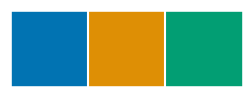

In [12]:
SPECIES = ['Adelie', 'Chinstrap', 'Gentoo']
PALETTE = {'Adelie': '#0173b2', 'Chinstrap': '#de8f05', 'Gentoo': '#029e73'}
MARKERS = {'Adelie': 'o', 'Chinstrap': 's', 'Gentoo': '^'}   # we need these in step 8

sns.palplot(PALETTE.values())
plt.show()

### Loading the data

In [13]:
from pathlib import Path

CSV = Path('data/penguins.csv')

if CSV.exists():                                 # the live-demo path: no network needed
    penguins = pd.read_csv(CSV)
else:                                            # first run: fetch once, then keep a copy
    penguins = sns.load_dataset('penguins')
    CSV.parent.mkdir(parents=True, exist_ok=True)
    penguins.to_csv(CSV, index=False)

penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


<div style="background:#e3f2fd;border-left:6px solid #90caf9;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>ℹ️ Where the data come from</strong><br/>
Body measurements of 344 adult penguins of the species <em>Pygoscelis adeliae</em> (Adélie), <em>P. antarcticus</em> (Chinstrap) and <em>P. papua</em> (Gentoo), collected 2007–2009 near Palmer Station, Antarctica, by Dr Kristen Gorman (Gorman, Williams &amp; Fraser 2014) and published as the <em>palmerpenguins</em> data set under <a href="https://creativecommons.org/publicdomain/zero/1.0/" target="_blank" rel="noopener">CC0</a>. See the <em>Sources</em> cell at the end.
</div>

## Step 2 — What kind of data is this?

Before choosing *any* chart type, we need to know what we are holding. Notebook 05
divided data into quantitative (continuous / discrete) and qualitative (nominal / ordinal) —
and that classification is what decides which plots are even admissible.

In [14]:
print(f'{penguins.shape[0]} rows × {penguins.shape[1]} columns')
penguins.info()

344 rows × 7 columns
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [15]:
# How many distinct values per column? A cheap way to spot the categorical ones.
penguins.nunique()

species                3
island                 3
bill_length_mm       164
bill_depth_mm         80
flipper_length_mm     55
body_mass_g           94
sex                    2
dtype: int64

In [16]:
for col in ['species', 'island', 'sex']:
    print(f'{col:>8}: {sorted(penguins[col].dropna().unique())}')

 species: ['Adelie', 'Chinstrap', 'Gentoo']
  island: ['Biscoe', 'Dream', 'Torgersen']
     sex: ['Female', 'Male']


<div style="background:#fff3e0;border-left:6px solid #ffb74d;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>🎯 Classify the columns</strong><br/>
Which columns are quantitative-continuous, which qualitative-nominal? Is any of them <em>ordinal</em>?
</div>

#### The answer, and what follows from it

<table style="border-collapse:collapse;margin:0.4em 0;">
  <thead>
    <tr>
      <th style="border:1px solid #333;padding:0.4em 0.8em;text-align:left;background:#eceff1;">Column</th>
      <th style="border:1px solid #333;padding:0.4em 0.8em;text-align:left;background:#eceff1;">Data type</th>
      <th style="border:1px solid #333;padding:0.4em 0.8em;text-align:left;background:#eceff1;">Charts that fit</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #333;padding:0.4em 0.8em;"><code>species</code>, <code>island</code>, <code>sex</code></td>
      <td style="border:1px solid #333;padding:0.4em 0.8em;">qualitative, <strong>nominal</strong> (3 / 3 / 2 levels, no order)</td>
      <td style="border:1px solid #333;padding:0.4em 0.8em;">counts as a bar chart or a table; as <em>grouping</em> via colour, marker shape or panel</td>
    </tr>
    <tr>
      <td style="border:1px solid #333;padding:0.4em 0.8em;"><code>bill_length_mm</code>, <code>bill_depth_mm</code>, <code>flipper_length_mm</code></td>
      <td style="border:1px solid #333;padding:0.4em 0.8em;">quantitative, <strong>continuous</strong> (mm)</td>
      <td style="border:1px solid #333;padding:0.4em 0.8em;">histogram, density, box/violin, scatter</td>
    </tr>
    <tr>
      <td style="border:1px solid #333;padding:0.4em 0.8em;"><code>body_mass_g</code></td>
      <td style="border:1px solid #333;padding:0.4em 0.8em;">quantitative, continuous, but recorded in 25 g steps</td>
      <td style="border:1px solid #333;padding:0.4em 0.8em;">same — but expect ties, so jitter the points</td>
    </tr>
  </tbody>
</table>

There is **no time column** and no natural order anywhere. Remember that for step 7:
*lines imply an order*, so nothing here may be connected by a line.

### Four numbers per column

`describe()` is the fastest overview there is — and, for 4 columns × 8 statistics, a
**table is the right visualisation**, exactly as argued in notebook 05.

In [17]:
penguins.describe().round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


### Two nominal variables: a contingency table

Nine numbers. A chart would add nothing here.

In [18]:
pd.crosstab(penguins['species'], penguins['island'], margins=True, margins_name='total')

island,Biscoe,Dream,Torgersen,total
species,,,,
Adelie,44,56,52,152
Chinstrap,0,68,0,68
Gentoo,124,0,0,124
total,168,124,52,344


<div style="background:#fff3e0;border-left:6px solid #ffb74d;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>⚠️ A finding, not a formality</strong><br/>
The design is <strong>unbalanced</strong>: Gentoos were only measured on Biscoe, Chinstraps only on Dream, Adélies everywhere. So "island" and "species" are confounded — any difference we later find between islands may simply be a difference between species. We therefore group by species from here on, and leave island out of the final chart.
</div>

## Step 3 — Where are the holes?

In [19]:
penguins.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [20]:
# Which rows are affected?
penguins[penguins.isna().any(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


Two rows have no measurements at all, nine more are missing only `sex`.
A **missingness map** shows at a glance whether the gaps are scattered or systematic —
the orange marks are the missing cells.

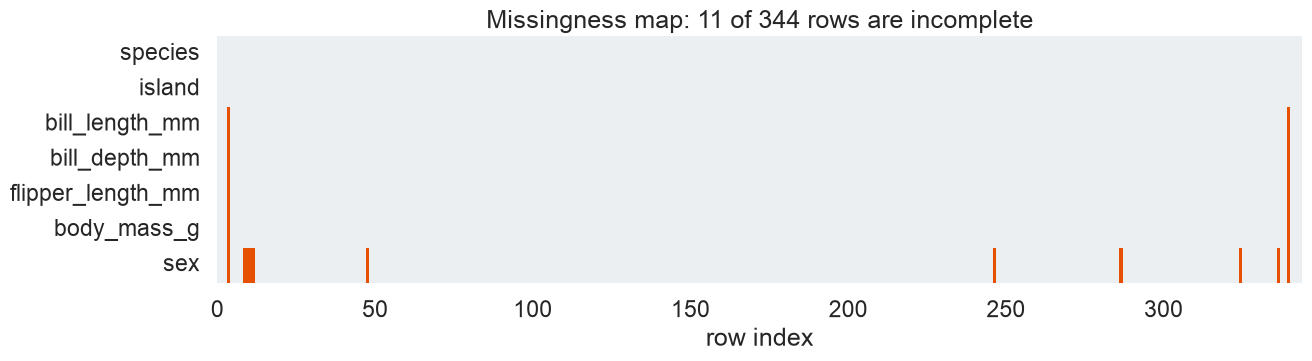

In [21]:
from matplotlib.colors import ListedColormap

fig, ax = plt.subplots(figsize=(14, 3.2))
sns.heatmap(penguins.isna().T, cbar=False, ax=ax,
            cmap=ListedColormap(['#eceff1', '#e65100']))   # neutral = present, orange = missing
ax.set_xlabel('row index')
ax.set_xticks(np.arange(0, len(penguins), 50))
ax.set_xticklabels(np.arange(0, len(penguins), 50), rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_title('Missingness map: 11 of 344 rows are incomplete')
plt.show()

The gaps are scattered, not clustered in one island or one species, so dropping
them does not bias the comparison. We keep a single clean frame and use it everywhere.

In [22]:
clean = penguins.dropna().reset_index(drop=True)
N = len(clean)
print(f'{len(penguins)} rows → {N} complete rows ({len(penguins) - N} dropped)')

344 rows → 333 complete rows (11 dropped)


<div style="background:#fff3e0;border-left:6px solid #ffb74d;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>⚠️ Missing data are invisible in a chart</strong><br/>
Every plotting function silently skips <code>NaN</code>. A reader cannot tell a bar built from 333 penguins from one built from 344. State the <em>n</em> you actually plotted — in the title, the caption or the axis label. We will put it into the final figure in step 11.
</div>

## Step 4 — One variable at a time

The first real chart is always univariate: *what does one column look like?*
We start with body mass and use `sns.histplot()` from notebook 04.

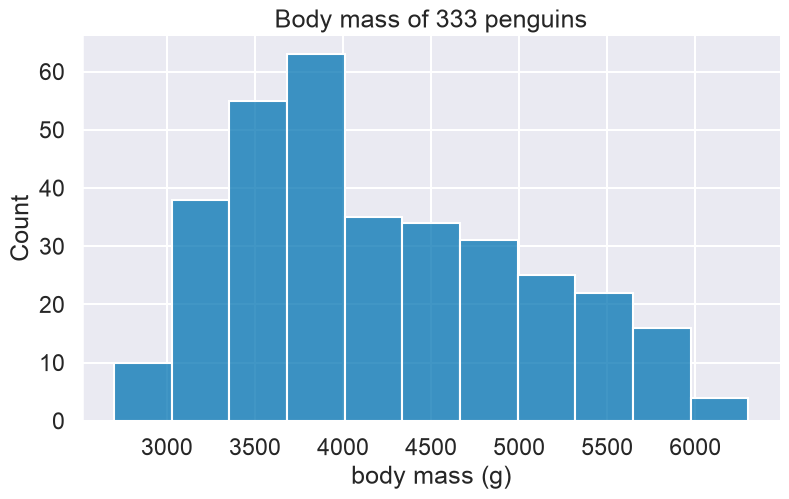

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=clean, x='body_mass_g', ax=ax, color='#0173b2')
ax.set_xlabel('body mass (g)')
ax.set_title('Body mass of 333 penguins')
sns.despine()
plt.show()

### The binning is a design decision, not a property of the data

`histplot()` picks a bin width for us. That choice changes the message — so it has to be
made consciously. Three panels, one row, a shared y-axis: notebook 05's layout rule says
panels sit **side by side** when the y-values are to be compared.

One catch: a *count* per bin depends on the bin width, so counts from different binnings
are not comparable. `stat='density'` normalises them and makes the shared y-axis honest.

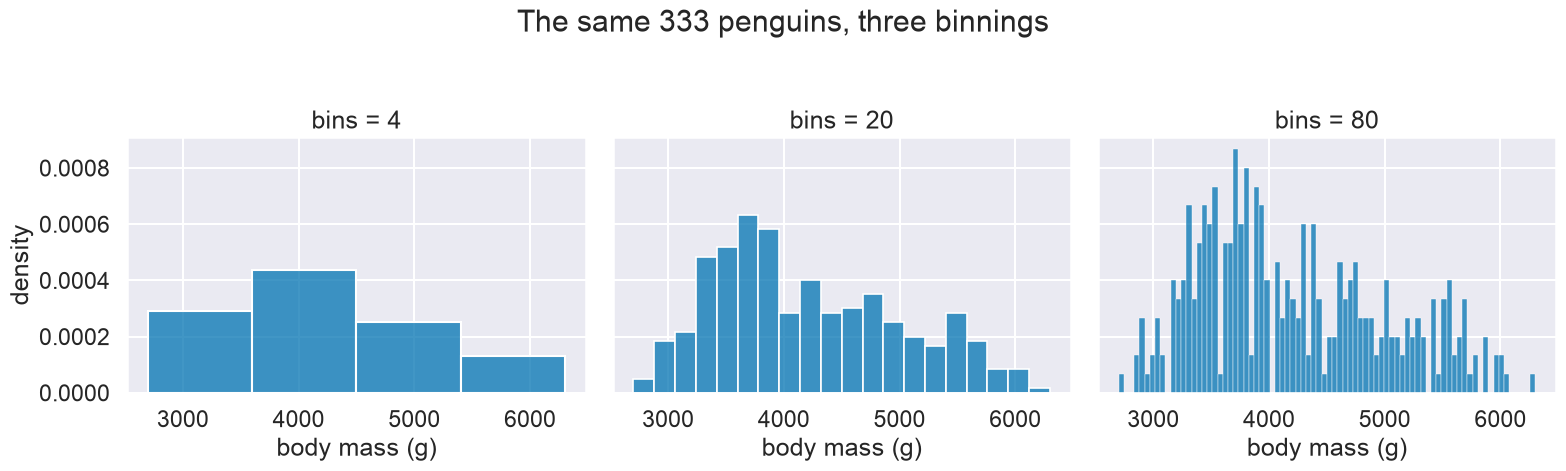

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)

for ax, bins in zip(axes, [4, 20, 80]):
    sns.histplot(data=clean, x='body_mass_g', bins=bins, stat='density', ax=ax,
                 color='#0173b2', edgecolor='white')
    ax.set_title(f'bins = {bins}')
    ax.set_xlabel('body mass (g)')

axes[0].set_ylabel('density')
fig.suptitle('The same 333 penguins, three binnings', y=1.04)
fig.tight_layout()
plt.show()

<div style="background:#fff3e0;border-left:6px solid #ffb74d;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>⚠️ What do you read off each panel?</strong><br/>
4 bins: one hump, "penguins weigh about 4 kg". 20 bins: the distribution is skewed, possibly <strong>two</strong> humps. 80 bins: mostly noise — plus an artefact, because the scale recorded mass in 25 g steps. Too few bins hide structure, too many invent it.
</div>

### Histogram, density and the raw values together

A kernel density estimate smooths the shape; a rug shows where the actual observations
sit, so the smoothing cannot hide a gap. Three layers in one `Axes` — the overlay
technique from notebook 04.

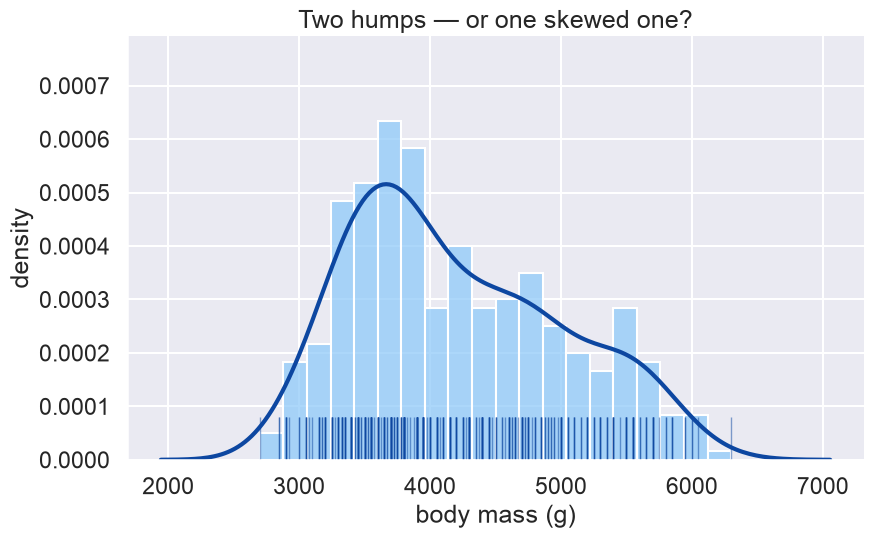

In [25]:
fig, ax = plt.subplots(figsize=(9.5, 5.5))

sns.histplot(data=clean, x='body_mass_g', bins=20, stat='density', ax=ax,
             color='#90caf9', edgecolor='white')
sns.kdeplot(data=clean, x='body_mass_g', ax=ax, color='#0d47a1', linewidth=3)
sns.rugplot(data=clean, x='body_mass_g', ax=ax, color='#0d47a1', height=0.1, alpha=0.5)

ax.set_xlabel('body mass (g)')
ax.set_ylabel('density')
ax.set_title('Two humps — or one skewed one?')
sns.despine()
plt.show()

<div style="background:#e3f2fd;border-left:6px solid #90caf9;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>ℹ️ A hypothesis to test</strong><br/>
The shoulder on the right suggests the 333 penguins are not one population but a <strong>mixture</strong>. The data set offers two candidate explanations: species and sex. Step 5 tries the first, step 6 the second.
</div>

## Step 5 — One variable, per group

Now we split body mass by species. This is the `boxplot → violinplot → swarmplot`
progression from notebook 04, and each step trades compactness for honesty.

One detail first: the categories must be **ordered deliberately**. Species is nominal, so
alphabetical order carries no meaning — ordering by the median does, and lets the reader
rank the groups by position instead of by reading labels.

In [26]:
order = clean.groupby('species')['body_mass_g'].median().sort_values().index.tolist()
print(order)

['Adelie', 'Chinstrap', 'Gentoo']


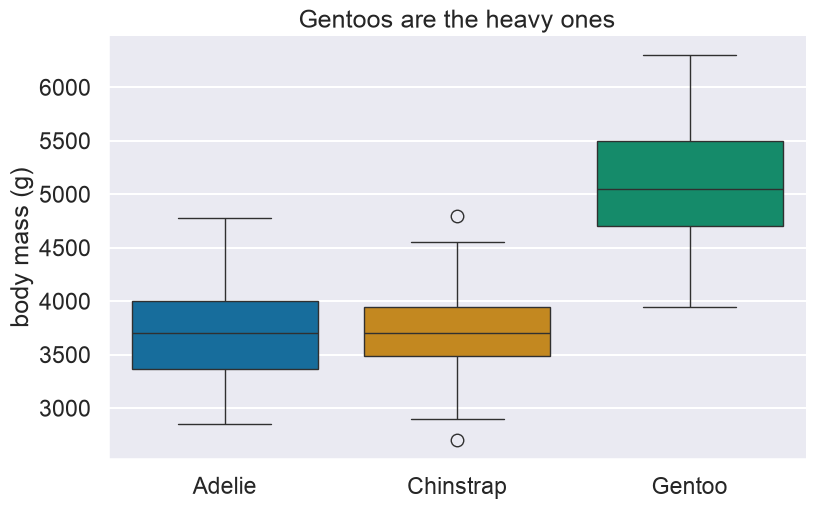

In [27]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=clean, x='species', y='body_mass_g', order=order,
            hue='species', palette=PALETTE, legend=False, ax=ax)
ax.set_xlabel('')
ax.set_ylabel('body mass (g)')
ax.set_title('Gentoos are the heavy ones')
sns.despine()
plt.show()

The box answers the question: the right-hand hump in step 4 was the Gentoos.
But a box shows five numbers only. A **violin** shows the whole density per group —
note how the Adélie and Chinstrap violins are wide at the top and bottom, which no box
can tell us.

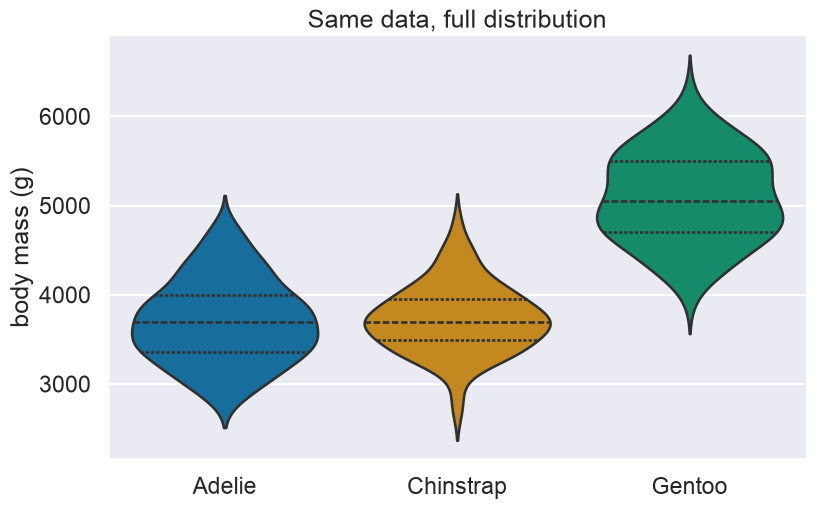

In [28]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.violinplot(data=clean, x='species', y='body_mass_g', order=order,
               hue='species', palette=PALETTE, legend=False,
               inner='quartile', density_norm='count', ax=ax)
ax.set_xlabel('')
ax.set_ylabel('body mass (g)')
ax.set_title('Same data, full distribution')
sns.despine()
plt.show()

And with 333 points we can simply **show all of them**. `swarmplot()` spreads
overlapping observations sideways; `boxplot()` underneath keeps the summary. Notebook 05's
advice on points applies: small symbols, and jitter when values are tied (body mass is
recorded in 25 g steps, so there are many ties).

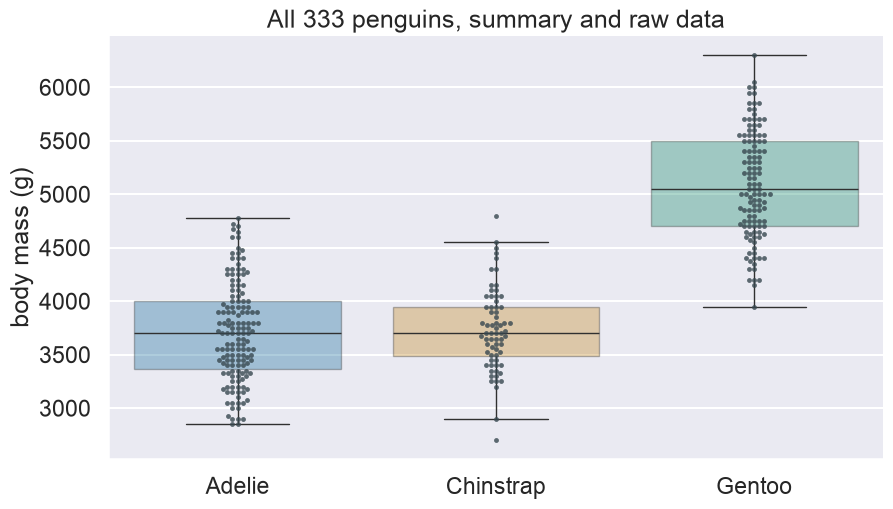

In [29]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=clean, x='species', y='body_mass_g', order=order, ax=ax,
            hue='species', palette=PALETTE, legend=False,
            boxprops=dict(alpha=0.35), showfliers=False)   # fliers would be drawn twice
sns.swarmplot(data=clean, x='species', y='body_mass_g', order=order, ax=ax,
              color='#37474f', size=3.5, alpha=0.8)
ax.set_xlabel('')
ax.set_ylabel('body mass (g)')
ax.set_title(f'All {N} penguins, summary and raw data')
sns.despine()
plt.show()

<div style="background:#fff3e0;border-left:6px solid #ffb74d;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>🎯 Which of the three would you project?</strong><br/>
Box for a dense comparison of many groups, violin when the <em>shape</em> is the point, swarm when <em>n</em> is small enough that every observation can be shown. Here: the swarm — it makes the group sizes visible, which the box hides entirely.
</div>

## Step 6 — A second grouping variable

The Adélie and Chinstrap distributions were suspiciously wide at both ends. Our
second hypothesis was sex. We move species to the x-axis (position) and give sex the
colour channel — **one variable per visual channel**, never two.

A split violin puts the two halves back to back, so the comparison happens at the
shortest possible distance for the eye.

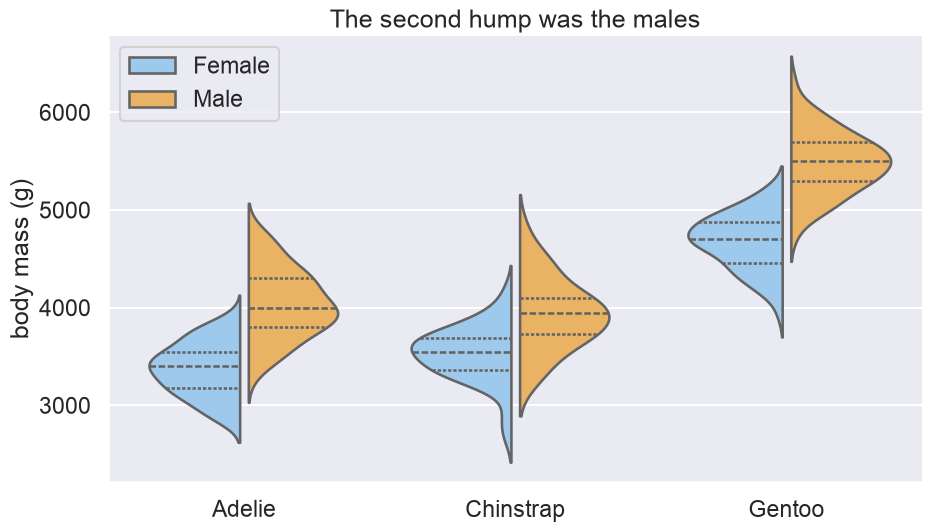

In [30]:
fig, ax = plt.subplots(figsize=(10.5, 5.8))
sns.violinplot(data=clean, x='species', y='body_mass_g', order=order,
               hue='sex', hue_order=['Female', 'Male'],
               palette={'Female': '#90caf9', 'Male': '#ffb74d'},
               split=True, inner='quartile', gap=0.08, ax=ax)
ax.set_xlabel('')
ax.set_ylabel('body mass (g)')
ax.set_title('The second hump was the males')
ax.legend(title='', loc='upper left', frameon=True)
sns.despine()
plt.show()

In [31]:
# The same finding as numbers — nine cells, so again a table beats a chart.
(clean.pivot_table(index='species', columns='sex', values='body_mass_g',
                   aggfunc=['mean', 'count'])
      .round(0))

mean          count     
sex        Female    Male Female Male
species                              
Adelie     3369.0  4043.0     73   73
Chinstrap  3527.0  3939.0     34   34
Gentoo     4680.0  5485.0     58   61

<div style="background:#e3f2fd;border-left:6px solid #90caf9;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>ℹ️ What we know after six steps</strong><br/>
Body mass separates Gentoo from the other two species, but Adélie and Chinstrap overlap almost completely — and within every species the males are roughly 400–800 g heavier. Mass alone will <strong>not</strong> answer our guiding question. We need the bill and flipper measurements.
</div>

## Step 7 — Two measurements at once, and a trap

Bill length against bill depth: both continuous, both in mm, 333 observations.
That is a scatter plot. We add a straight fit through all the data with
`sns.regplot()` to summarise the trend.

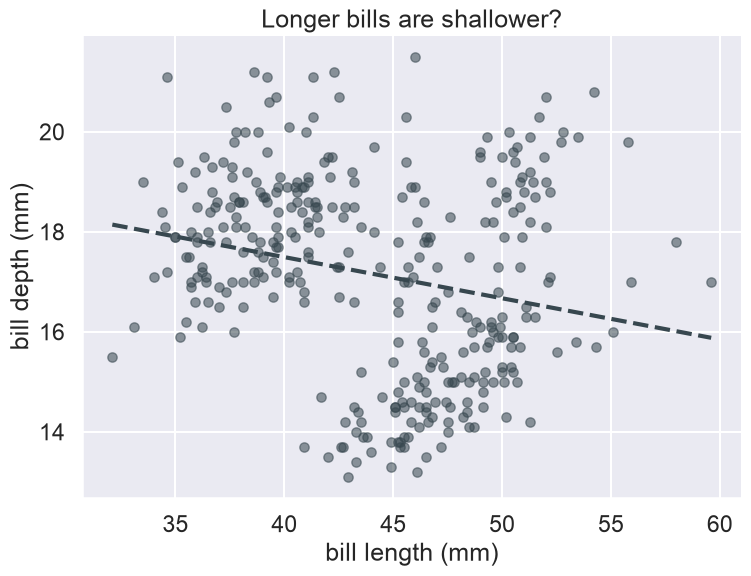

In [32]:
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.regplot(data=clean, x='bill_length_mm', y='bill_depth_mm', ax=ax, ci=None,
            scatter_kws=dict(color='#37474f', alpha=0.55, s=45),
            line_kws=dict(color='#37474f', linewidth=3, linestyle='--'))
ax.set_xlabel('bill length (mm)')
ax.set_ylabel('bill depth (mm)')
ax.set_title('Longer bills are shallower?')
sns.despine()
plt.show()

In [33]:
r = clean['bill_length_mm'].corr(clean['bill_depth_mm'])
print(f'all penguins pooled:  r = {r:+.2f}')

all penguins pooled:  r = -0.23


A clear negative correlation. Now we colour the very same points by species —
nothing else changes.

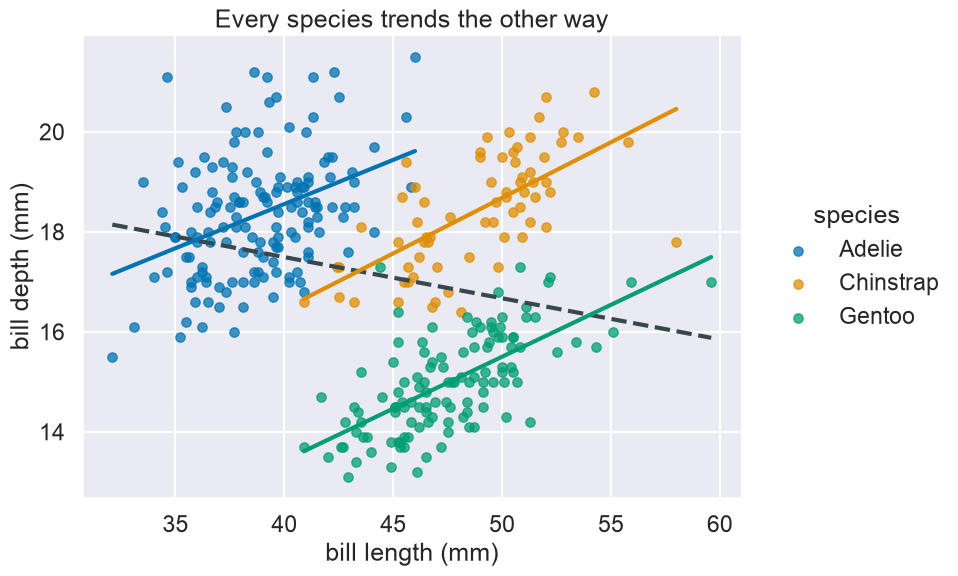

In [34]:
fig, ax = plt.subplots(figsize=(8.5, 6))

# the misleading pooled fit, kept for reference
sns.regplot(data=clean, x='bill_length_mm', y='bill_depth_mm', ax=ax, ci=None,
            scatter=False, line_kws=dict(color='#37474f', linewidth=3, linestyle='--'))

for species in SPECIES:
    group = clean[clean['species'] == species]
    sns.regplot(data=group, x='bill_length_mm', y='bill_depth_mm', ax=ax, ci=None,
                scatter_kws=dict(color=PALETTE[species], alpha=0.75, s=45),
                line_kws=dict(color=PALETTE[species], linewidth=3),
                label=species)

ax.set_xlabel('bill length (mm)')
ax.set_ylabel('bill depth (mm)')
ax.set_title('Every species trends the other way')
# The legend goes into the margin — it must not cover data (notebook 05, Legends).
ax.legend(title='species', loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
sns.despine()
plt.show()

In [35]:
print(f'all penguins pooled:  r = {r:+.2f}')
for species in SPECIES:
    group = clean[clean['species'] == species]
    g = group['bill_length_mm'].corr(group['bill_depth_mm'])
    print(f'{species:<20} r = {g:+.2f}   (n = {len(group)})')

all penguins pooled:  r = -0.23
Adelie               r = +0.39   (n = 146)
Chinstrap            r = +0.65   (n = 68)
Gentoo               r = +0.65   (n = 119)


<div style="background:#fff3e0;border-left:6px solid #ffb74d;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>⚠️ Simpson's paradox</strong><br/>
Pooled over all penguins the relationship is negative (r = −0.23); within <em>every single</em> species it is clearly positive (+0.39, +0.65, +0.64). The aggregate does not just weaken the effect, it <strong>reverses its sign</strong>. The dashed line is a true regression line and a false statement about penguins.<br/>This is why an analysis chart is drawn <em>before</em> a summary statistic is trusted — and why a grouping variable gets its own visual channel.
</div>

### The same thing as a faceted plot

`lmplot()` is `regplot()` on a `FacetGrid`: one panel per species, shared axes.
Overlay or facet? Overlay when the groups are to be compared directly, facets when
the panels get crowded. Notice the layout rule again — the y-values are compared, so
the panels sit side by side.

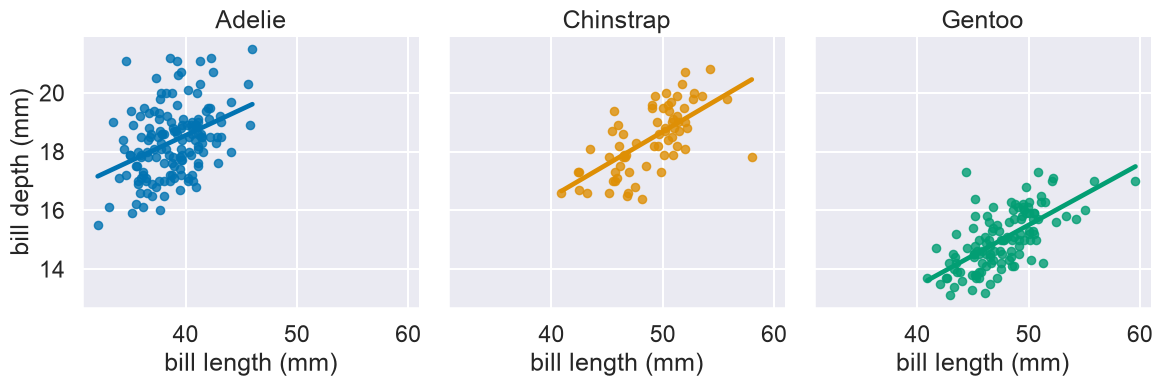

In [36]:
g = sns.lmplot(data=clean, x='bill_length_mm', y='bill_depth_mm',
               col='species', col_order=SPECIES, hue='species', palette=PALETTE,
               height=4.2, aspect=0.95, ci=None,
               scatter_kws=dict(s=35, alpha=0.8))
g.set_axis_labels('bill length (mm)', 'bill depth (mm)')
g.set_titles('{col_name}')
plt.show()

## Step 8 — Make the encoding robust

Our charts now carry the species in **colour only**. That fails for a colour-blind
reader, in a greyscale printout, and on a beamer whose colour balance is off. Notebook 05's
answer is the *redundant encoding*: map the same variable to a second visual channel.
Marker shape costs nothing and survives everything.

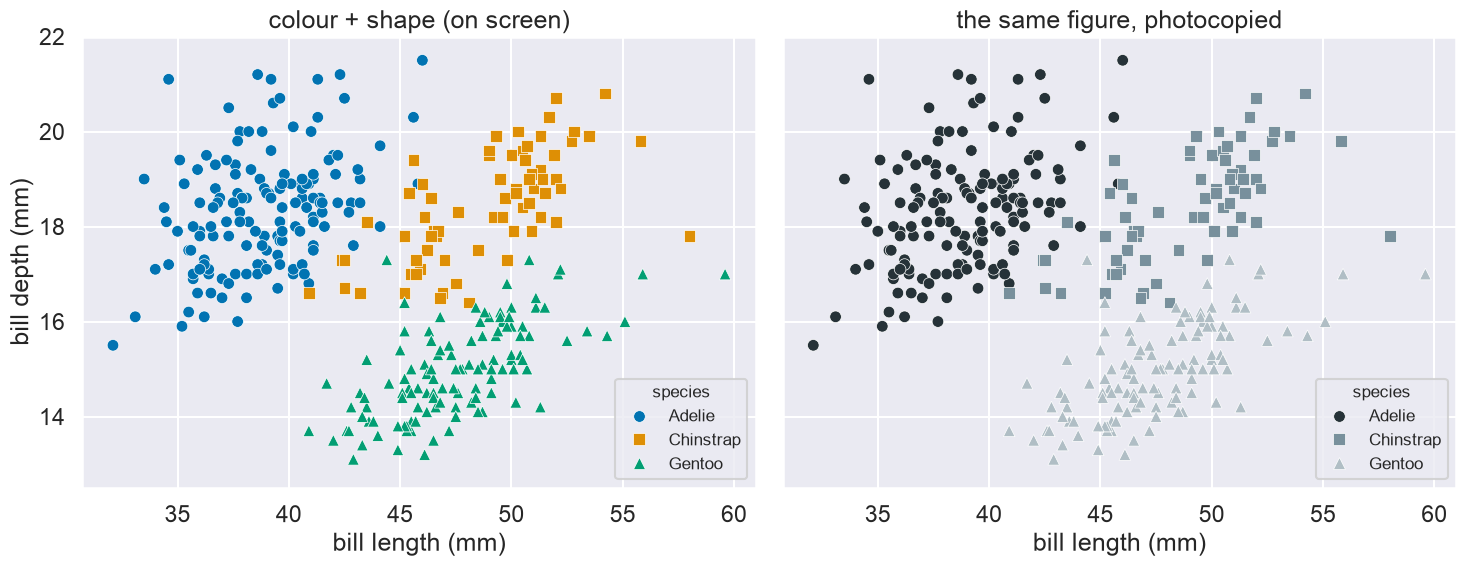

In [37]:
greyscale = {'Adelie': '#263238', 'Chinstrap': '#78909c', 'Gentoo': '#b0bec5'}

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

for ax, palette, title in zip(axes,
                              [PALETTE, greyscale],
                              ['colour + shape (on screen)', 'the same figure, photocopied']):
    sns.scatterplot(data=clean, x='bill_length_mm', y='bill_depth_mm', ax=ax,
                    hue='species', hue_order=SPECIES, palette=palette,
                    style='species', markers=MARKERS, s=70,
                    edgecolor='white', linewidth=0.5)
    ax.set_title(title)
    ax.set_xlabel('bill length (mm)')
    ax.set_ylim(12.5, 22)                      # free space for the legend, below the data
    ax.legend(title='species', loc='lower right', fontsize=12, title_fontsize=12)

axes[0].set_ylabel('bill depth (mm)')
axes[1].set_ylabel('')
fig.tight_layout()
plt.show()

<div style="background:#e3f2fd;border-left:6px solid #90caf9;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>ℹ️ Why this palette</strong><br/>
The three colours come from seaborn's <code>colorblind</code> palette, which keeps its hues distinguishable under the common forms of colour-vision deficiency. Even so, the shapes do the heavy lifting in the right-hand panel: ordering the greys light-to-dark would still not tell the reader <em>which</em> grey is Chinstrap, whereas a square is a square.
</div>

## Step 9 — Axes: units, zero, aspect ratio

### Does the axis have to start at zero?

Notebook 05 says axis ranges should start at 0 *unless there is a good reason*. The rule
is really about the **encoding**, not the axis: a bar encodes its value as a *length*, so
cutting the bar lies about the ratio. A scatter point encodes its value as a *position*,
so a zoomed window is legitimate — and often necessary.

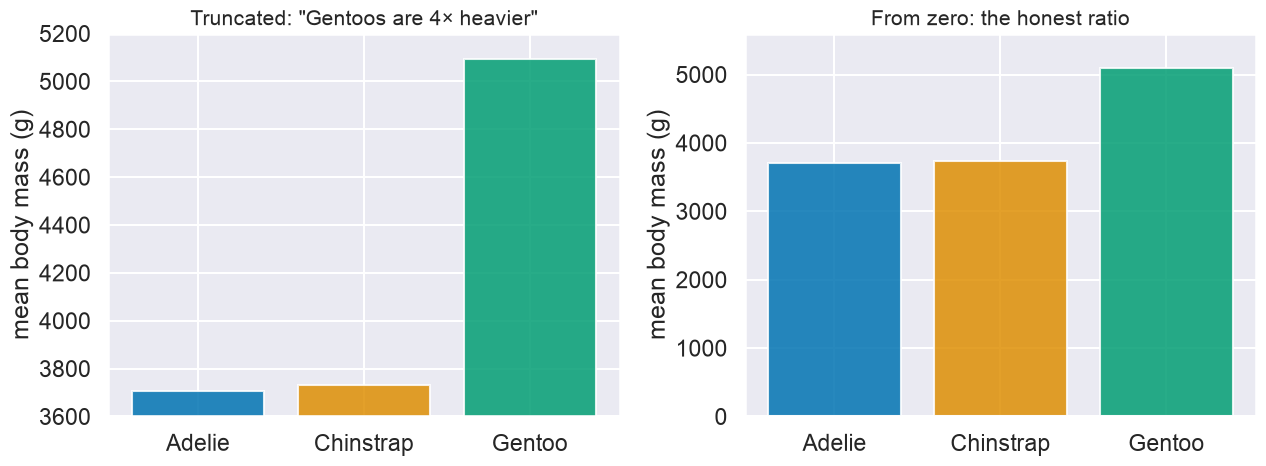

In [38]:
means = clean.groupby('species')['body_mass_g'].mean().reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, ylim, title in zip(axes,
                           [(3600, 5200), (0, 5600)],
                           ['Truncated: "Gentoos are 4× heavier"', 'From zero: the honest ratio']):
    ax.bar(means.index, means.values, color=[PALETTE[s] for s in means.index], alpha=0.85)
    ax.set_ylim(*ylim)
    ax.set_ylabel('mean body mass (g)')
    ax.set_title(title, fontsize=15)

fig.tight_layout()
plt.show()

Same three numbers, two readings. The left panel is the single most common way to
mislead with a chart — and it needs no false data at all, only `set_ylim()`.

### Same unit on both axes → aspect ratio 1:1

Bill length and bill depth are both in mm. Then 1 mm should be the same physical distance
in both directions, otherwise the shape of a cluster is an artefact of the figure size.
`ax.set_aspect('equal')` enforces it.

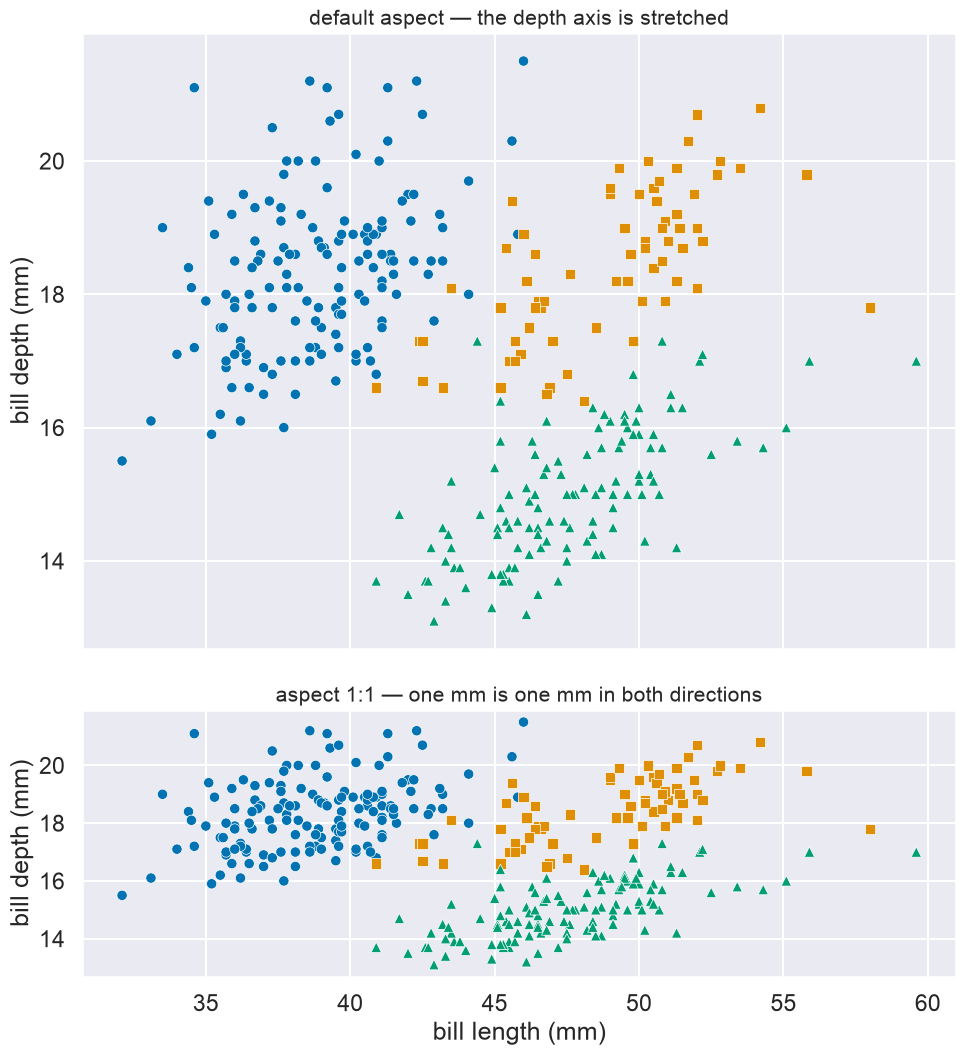

In [39]:
# Stacked, not side by side: both panels keep the same width, so the only
# difference the eye has to judge is the height.
fig, axes = plt.subplots(2, 1, figsize=(10, 11), sharex=True,
                         gridspec_kw=dict(height_ratios=[2, 1]))

for ax, equal in zip(axes, [False, True]):
    sns.scatterplot(data=clean, x='bill_length_mm', y='bill_depth_mm', ax=ax,
                    hue='species', hue_order=SPECIES, palette=PALETTE,
                    style='species', markers=MARKERS, s=55, legend=False,
                    edgecolor='white', linewidth=0.5)
    ax.set_ylabel('bill depth (mm)')
    if equal:
        ax.set_aspect('equal')
        ax.set_title('aspect 1:1 — one mm is one mm in both directions', fontsize=15)
    else:
        ax.set_title('default aspect — the depth axis is stretched', fontsize=15)

axes[1].set_xlabel('bill length (mm)')
fig.tight_layout()
plt.show()

<div style="background:#fff3e0;border-left:6px solid #ffb74d;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>⚠️ Read both panels again</strong><br/>
On the left the Gentoo cloud looks round and the Adélie/Chinstrap clouds look tall; on the right all three are flat, because the bills vary by ~28 mm in length but only ~8 mm in depth. The left panel exaggerates the depth differences by a factor of three — the same distortion notebook 05 demonstrates in its <em>Aspect Ratio</em> figure.
</div>

## Step 10 — All pairs at once

With four measurements there are six pairs. `pairplot()` draws all of them plus the
marginal distributions — the single most useful *analysis* chart there is, and one you
would never project as a result. `corner=True` drops the mirrored upper triangle: the
same six panels twice would be a redundant **layout**, not a redundant encoding.

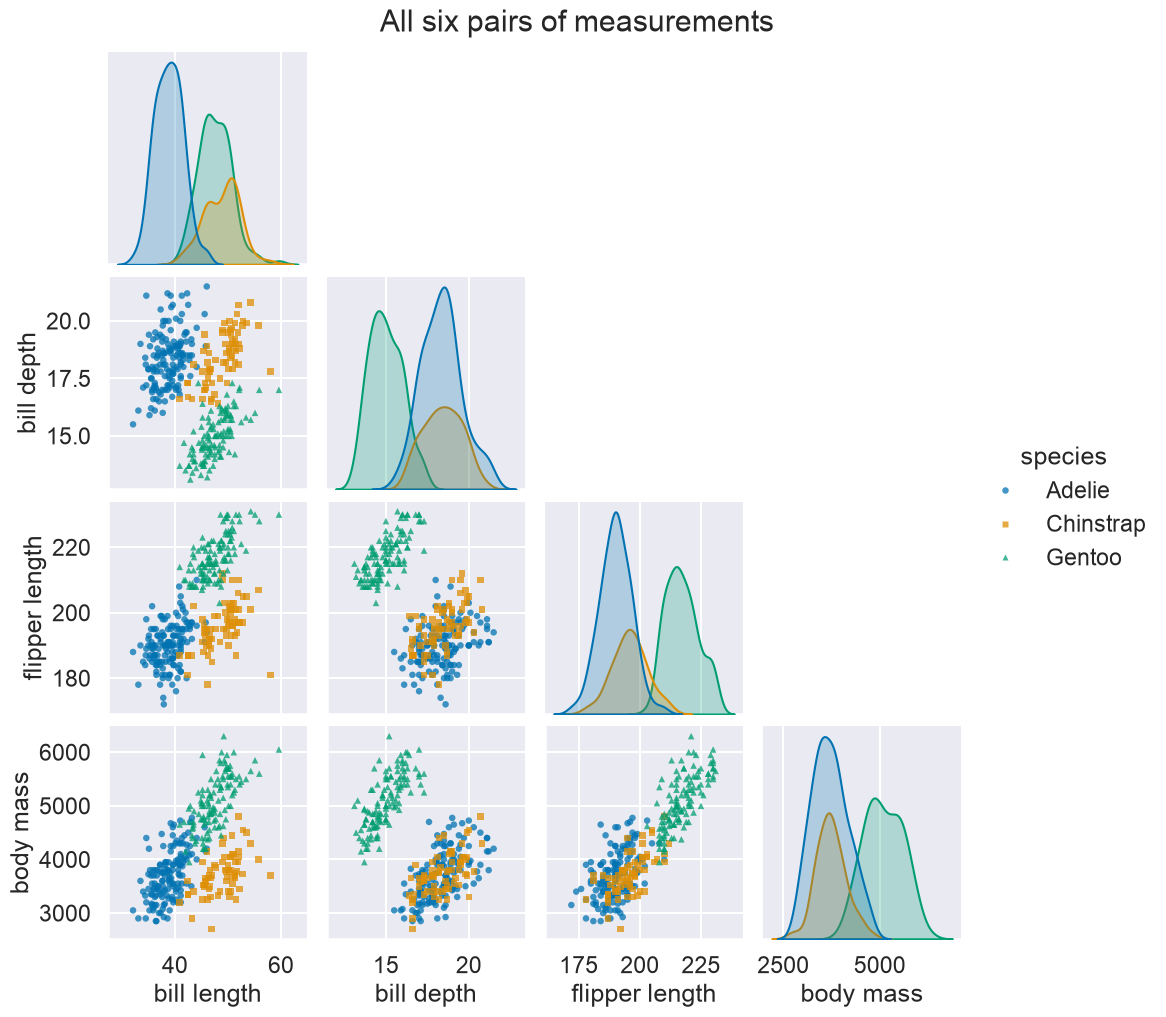

In [40]:
MEASURES = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Sixteen panel labels fight for very little room: shorten them first.
SHORT = {'bill_length_mm': 'bill length', 'bill_depth_mm': 'bill depth',
         'flipper_length_mm': 'flipper length', 'body_mass_g': 'body mass'}

g = sns.pairplot(clean.rename(columns=SHORT), vars=list(SHORT.values()),
                 hue='species', hue_order=SPECIES,
                 palette=PALETTE, markers=list(MARKERS.values()),
                 corner=True, diag_kind='kde', height=2.5,
                 plot_kws=dict(s=22, alpha=0.75, edgecolor='none'))
g.figure.suptitle('All six pairs of measurements', y=1.02)
plt.show()

<div style="background:#fff3e0;border-left:6px solid #ffb74d;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>🎯 Which pair separates the three species best?</strong><br/>
Look for the panel with three clouds that barely touch. Candidates: bill length × bill depth, and flipper length × bill length.
</div>

### The correlation matrix

Sixteen numbers, so a heatmap is defensible — but only with two precautions from
notebook 05: a **diverging** palette for signed values, centred on 0 and symmetric
(`vmin=-1, vmax=1`), and the numbers printed on top, because colour intensity is read
poorly. Colour for the pattern, digits for the value: a redundant encoding again.

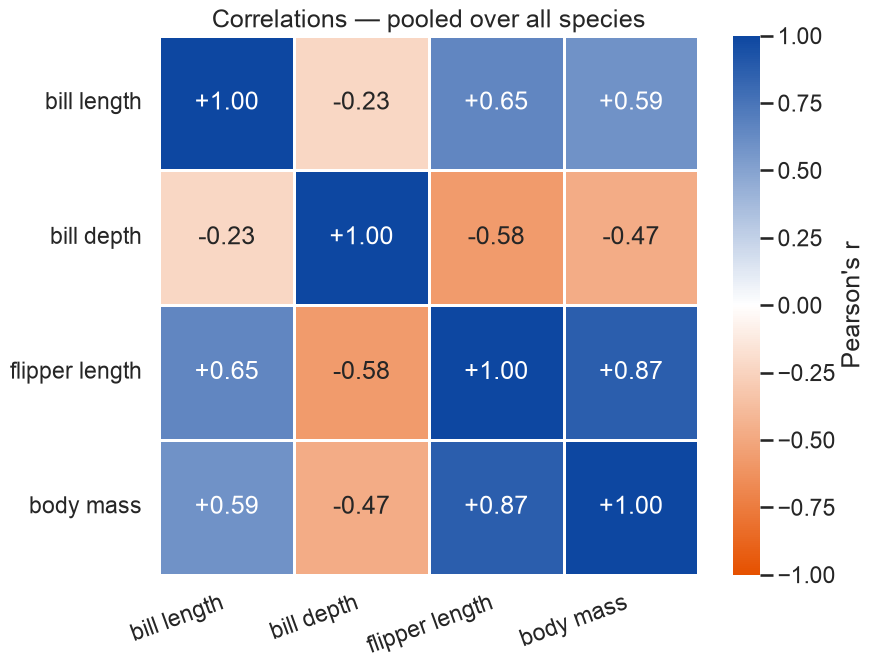

In [41]:
from matplotlib.colors import LinearSegmentedColormap

# The same orange–white–blue diverging scale as in notebook 05.
diverging = LinearSegmentedColormap.from_list('orange_blue', ['#e65100', '#ffffff', '#0d47a1'])

corr = clean[MEASURES].corr().rename(columns=SHORT, index=SHORT)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, ax=ax, cmap=diverging, vmin=-1, vmax=1, center=0,
            annot=True, fmt='+.2f', square=True, linewidths=1, linecolor='white',
            cbar_kws=dict(label="Pearson's r"))
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_title('Correlations — pooled over all species')
plt.show()

<div style="background:#fff3e0;border-left:6px solid #ffb74d;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>⚠️ This matrix inherits the trap from step 7</strong><br/>
Every cell is computed over the pooled data, so the bill-length × bill-depth cell reads −0.23 — the sign that step 7 showed to be wrong. A correlation heatmap of a grouped data set needs one matrix <em>per group</em>, or a warning in the caption.
</div>

## Step 11 — From analysis chart to message chart

We have our answer: **bill length and bill depth together separate all three
species**, which neither does alone. Everything so far was drawn to find that out. Now we
build the one figure that says it — in four passes, so you can see each decision land.

#### Pass 1 — the data, and nothing else

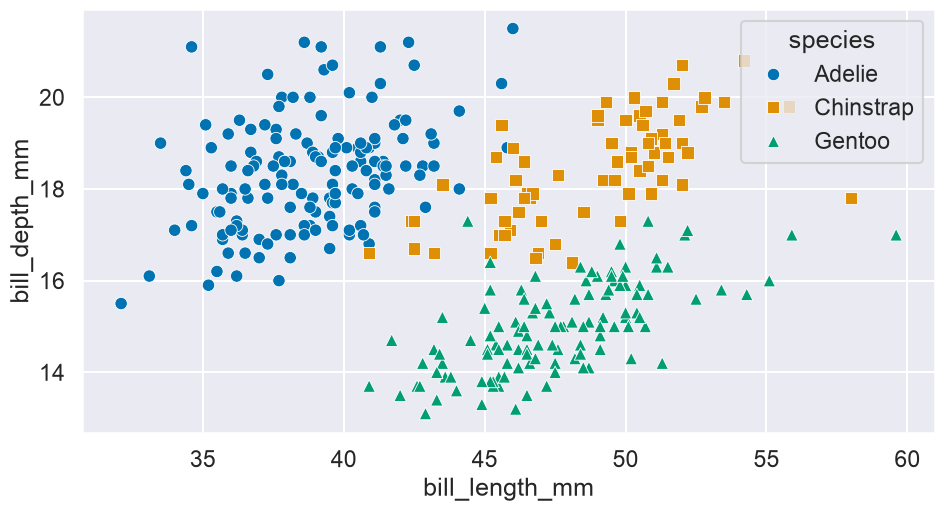

In [42]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.scatterplot(data=clean, x='bill_length_mm', y='bill_depth_mm', ax=ax,
                hue='species', hue_order=SPECIES, palette=PALETTE,
                style='species', markers=MARKERS, s=80,
                edgecolor='white', linewidth=0.6)
plt.show()

#### Pass 2 — labels with units, and a title that states the finding

A title should say what the reader is supposed to take away, not name the variables —
the axis labels already do that. "Bill depth vs. bill length" is a caption; the sentence
below is a result.

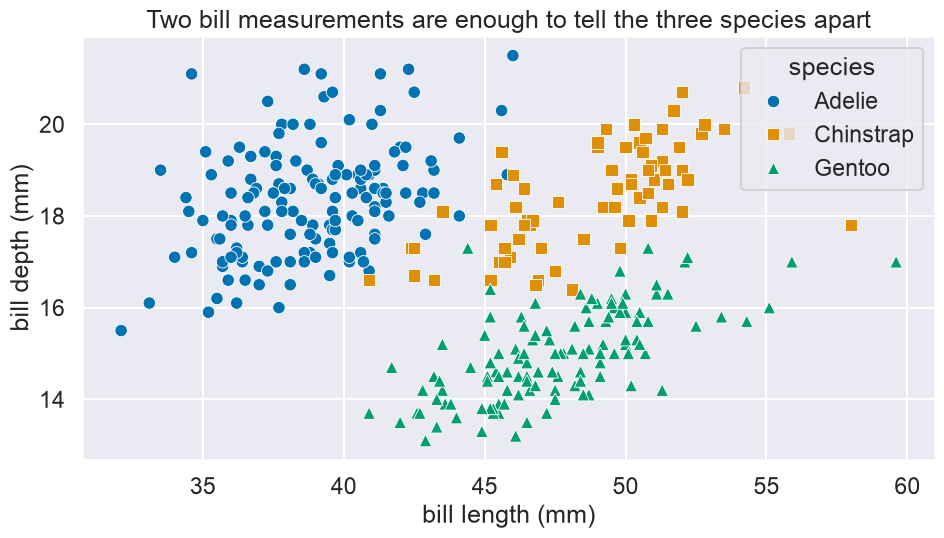

In [43]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.scatterplot(data=clean, x='bill_length_mm', y='bill_depth_mm', ax=ax,
                hue='species', hue_order=SPECIES, palette=PALETTE,
                style='species', markers=MARKERS, s=80,
                edgecolor='white', linewidth=0.6)

ax.set_xlabel('bill length (mm)')
ax.set_ylabel('bill depth (mm)')
ax.set_title('Two bill measurements are enough to tell the three species apart')
plt.show()

#### Pass 3 — the legend goes to the data

Notebook 05: *"if legend entries refer to single objects, placing the legend next to the
corresponding object makes it easier for the reader to map legend entries to display
objects"*. Three clusters, three labels — so the legend box can go away entirely, and
with it the eye's round trip between box and data. The axis limits are widened by hand
to make room for the labels, so that they never sit on top of a data point.

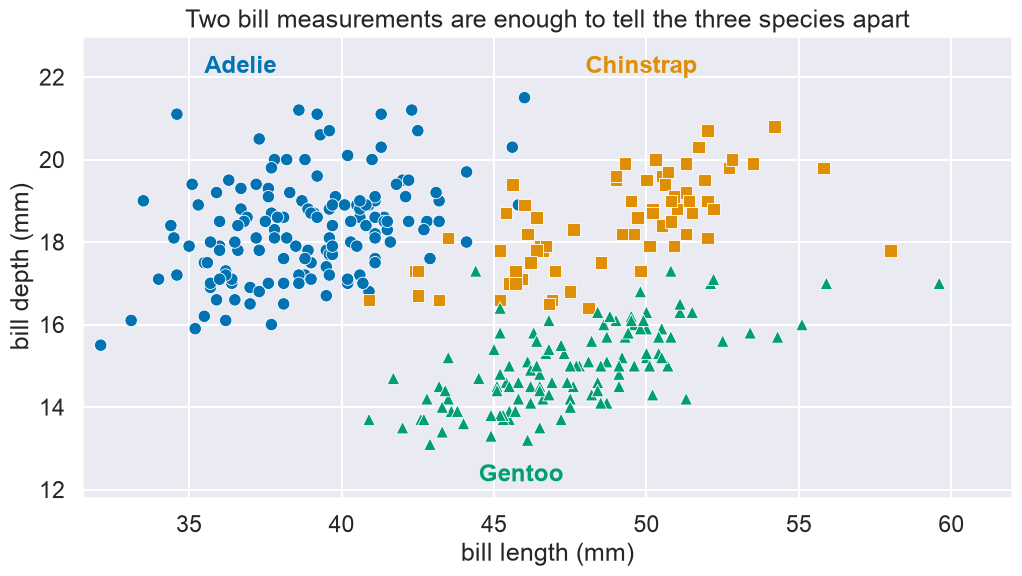

In [44]:
LABEL_POS = {           # (x, y) in data coordinates: directly above / below its cluster
    'Adelie':    (35.5, 22.1),
    'Chinstrap': (48.0, 22.1),
    'Gentoo':    (44.5, 12.2),
}

fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(data=clean, x='bill_length_mm', y='bill_depth_mm', ax=ax,
                hue='species', hue_order=SPECIES, palette=PALETTE,
                style='species', markers=MARKERS, s=80, legend=False,
                edgecolor='white', linewidth=0.6)

for species, (x, y) in LABEL_POS.items():
    ax.text(x, y, species, color=PALETTE[species], fontsize=17, fontweight='bold')

ax.set_xlim(31.5, 62)
ax.set_ylim(11.8, 23)
ax.set_xlabel('bill length (mm)')
ax.set_ylabel('bill depth (mm)')
ax.set_title('Two bill measurements are enough to tell the three species apart')
plt.show()

#### Pass 4 — the finishing touches

Aspect 1:1 because both axes are mm (step 9), the grid pushed behind the data, the frame
reduced to two spines, and a source note carrying *n* and the data credit — the two things
that make a figure checkable.

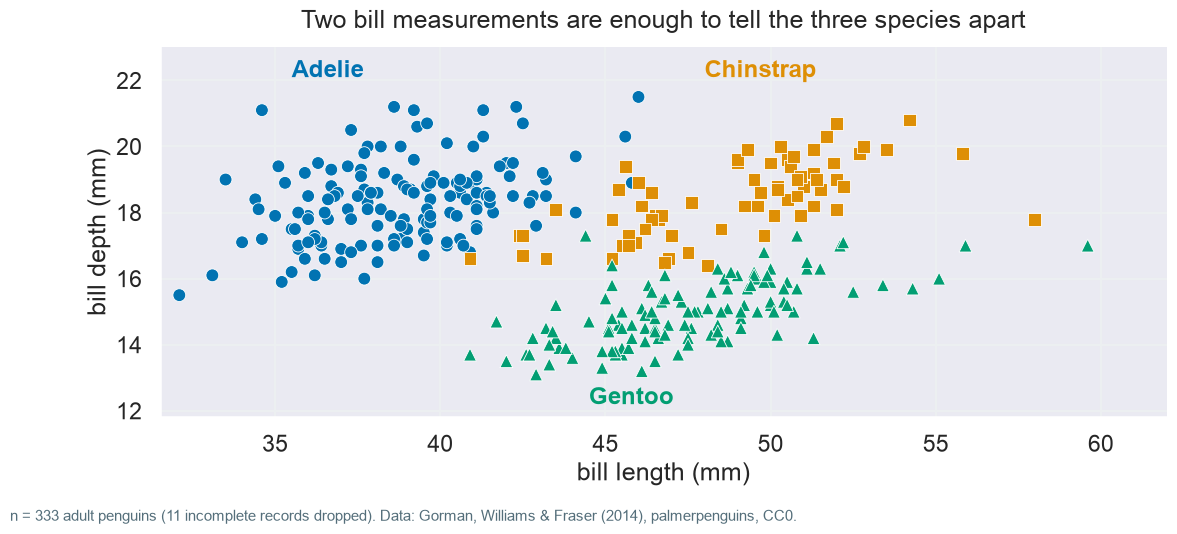

In [45]:
fig, ax = plt.subplots(figsize=(13, 5.6))

sns.scatterplot(data=clean, x='bill_length_mm', y='bill_depth_mm', ax=ax,
                hue='species', hue_order=SPECIES, palette=PALETTE,
                style='species', markers=MARKERS, s=85, legend=False,
                edgecolor='white', linewidth=0.6, zorder=3)

for species, (x, y) in LABEL_POS.items():
    ax.text(x, y, species, color=PALETTE[species], fontsize=17, fontweight='bold', zorder=4)

ax.set_xlim(31.5, 62)
ax.set_ylim(11.8, 23)
ax.set_aspect('equal')                      # both axes are mm
ax.set_xlabel('bill length (mm)')
ax.set_ylabel('bill depth (mm)')
ax.set_title('Two bill measurements are enough to tell the three species apart',
             pad=14)
ax.grid(True, color='#eceff1', zorder=0)
sns.despine()

fig.text(0.01, -0.02,
         f'n = {N} adult penguins (11 incomplete records dropped). '
         'Data: Gorman, Williams & Fraser (2014), palmerpenguins, CC0.',
         fontsize=11, color='#546e7a')

plt.show()

### Saving it

`plt.savefig()` instead of `plt.show()`, as in notebook 04 — `bbox_inches='tight'` so the
source note is not clipped, and 300 dpi so the figure survives a projector and a print.

In [46]:
fig.savefig('penguin_bills.png', dpi=300, bbox_inches='tight')
print('written:', Path('penguin_bills.png').stat().st_size // 1024, 'KiB')

written: 379 KiB


In [47]:
# Clean up again — we do not want the file in the repository.
Path('penguin_bills.png').unlink()

## Step 12 — The same data, done badly

Two quick counterexamples, both built from the data we just analysed.

#### Angles and areas instead of positions

Cleveland and McGill's ranking (notebook 05, *Position and Size*) puts position on a
common scale first and angle/area near the bottom. Three group sizes in a pie versus the
same three as bars:

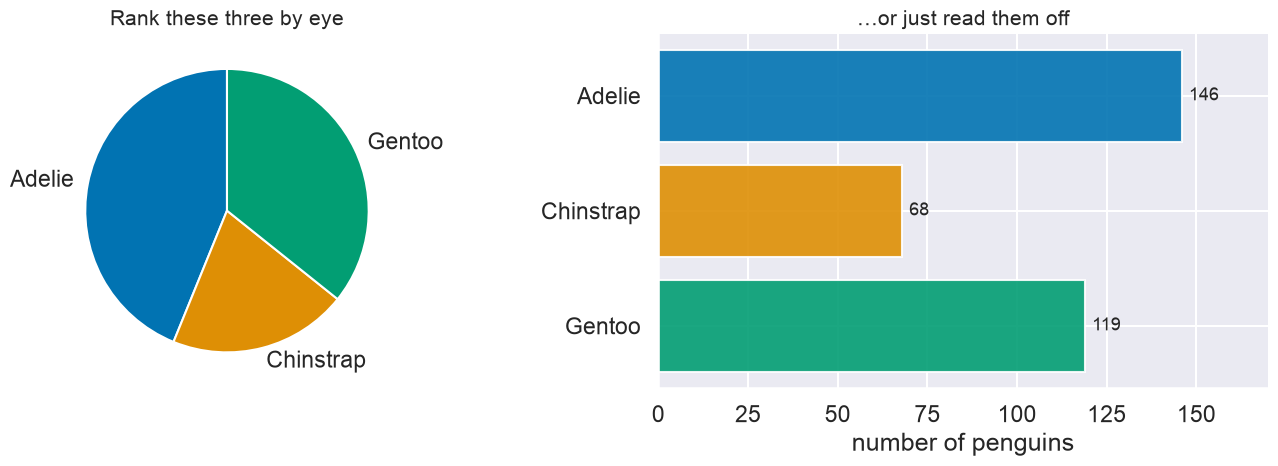

In [48]:
counts = clean['species'].value_counts().reindex(SPECIES)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(counts, labels=counts.index, startangle=90,
            colors=[PALETTE[s] for s in counts.index])
axes[0].set_title('Rank these three by eye', fontsize=15)

axes[1].barh(counts.index[::-1], counts.values[::-1],
             color=[PALETTE[s] for s in counts.index[::-1]], alpha=0.9)
axes[1].set_xlabel('number of penguins')
axes[1].set_title('…or just read them off', fontsize=15)
axes[1].bar_label(axes[1].containers[0], padding=5, fontsize=13)
axes[1].set_xlim(0, 170)                    # room for the value labels
sns.despine(ax=axes[1])

fig.tight_layout()
plt.show()

#### A rainbow for a quantity

Body mass is a quantity, so it needs a **sequential** palette whose lightness increases
monotonically. `jet` does not: it has bright bands in the middle and dark ends, so the eye
invents boundaries that are not in the data.

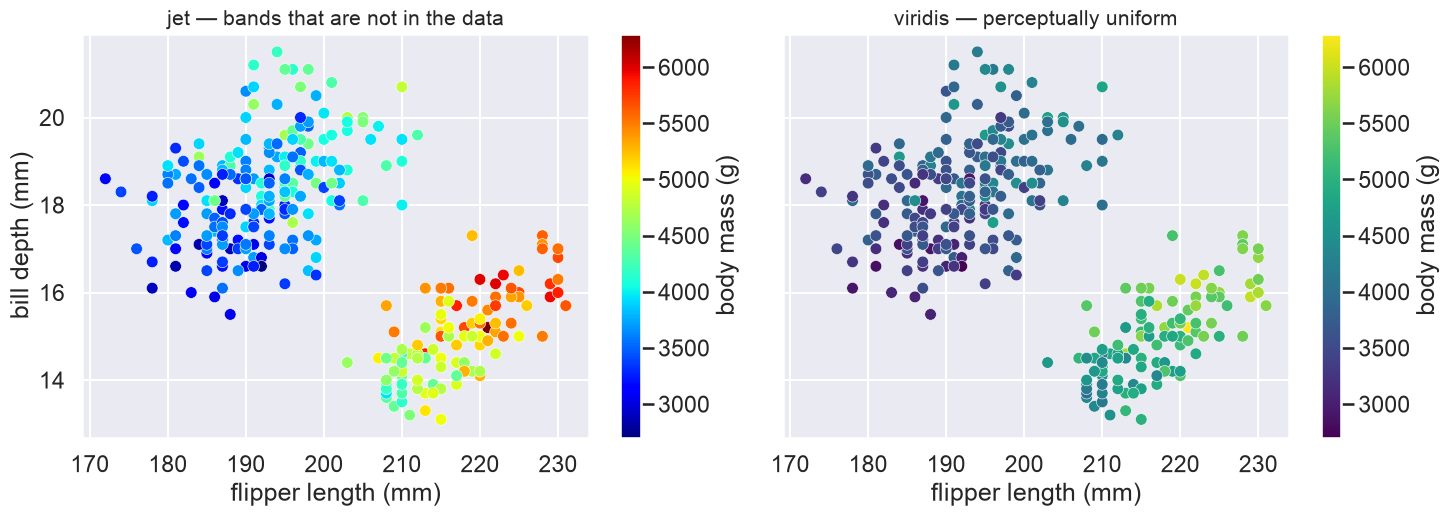

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

for ax, cmap, title in zip(axes, ['jet', 'viridis'],
                           ['jet — bands that are not in the data',
                            'viridis — perceptually uniform']):
    points = ax.scatter(clean['flipper_length_mm'], clean['bill_depth_mm'],
                        c=clean['body_mass_g'], cmap=cmap, s=70,
                        edgecolor='white', linewidth=0.4)
    ax.set_xlabel('flipper length (mm)')
    ax.set_title(title, fontsize=15)
    fig.colorbar(points, ax=ax, label='body mass (g)')

axes[0].set_ylabel('bill depth (mm)')
fig.tight_layout()
plt.show()

<div style="background:#e3f2fd;border-left:6px solid #90caf9;border-radius:6px;padding:0.7em 1.1em;margin:0.8em 0;">
<strong>ℹ️ And a third flaw in both panels</strong><br/>
Colour is carrying a <em>third</em> quantitative variable on top of two positional ones. That is three continuous variables in one plot — readable in principle, but the pairplot of step 10 answers the same question with far less effort from the reader.
</div>

## Recap

<table style="border-collapse:collapse;margin:0.4em 0;font-size:0.95em;">
  <thead>
    <tr>
      <th style="border:1px solid #333;padding:0.4em 0.7em;text-align:left;background:#eceff1;">Step</th>
      <th style="border:1px solid #333;padding:0.4em 0.7em;text-align:left;background:#eceff1;">What the chart showed</th>
      <th style="border:1px solid #333;padding:0.4em 0.7em;text-align:left;background:#eceff1;">The lesson</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">2</td><td style="border:1px solid #333;padding:0.4em 0.7em;">species and island are confounded</td><td style="border:1px solid #333;padding:0.4em 0.7em;">classify the data types <em>before</em> choosing a chart</td></tr>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">3</td><td style="border:1px solid #333;padding:0.4em 0.7em;">11 incomplete records</td><td style="border:1px solid #333;padding:0.4em 0.7em;">missing data are invisible in a plot — state <em>n</em></td></tr>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">4</td><td style="border:1px solid #333;padding:0.4em 0.7em;">4 / 20 / 80 bins</td><td style="border:1px solid #333;padding:0.4em 0.7em;">the binning is your decision, and it changes the message</td></tr>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">5</td><td style="border:1px solid #333;padding:0.4em 0.7em;">box → violin → swarm</td><td style="border:1px solid #333;padding:0.4em 0.7em;">order categories by value; show the raw data when you can</td></tr>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">6</td><td style="border:1px solid #333;padding:0.4em 0.7em;">the second hump was sex</td><td style="border:1px solid #333;padding:0.4em 0.7em;">one variable per visual channel</td></tr>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">7</td><td style="border:1px solid #333;padding:0.4em 0.7em;">r = −0.23 pooled, +0.4…+0.65 per species</td><td style="border:1px solid #333;padding:0.4em 0.7em;">Simpson's paradox: aggregation can flip a sign</td></tr>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">8</td><td style="border:1px solid #333;padding:0.4em 0.7em;">colour vs. colour + shape</td><td style="border:1px solid #333;padding:0.4em 0.7em;">redundant encodings cost nothing and buy robustness</td></tr>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">9</td><td style="border:1px solid #333;padding:0.4em 0.7em;">truncated bars, stretched aspect</td><td style="border:1px solid #333;padding:0.4em 0.7em;">zero matters for lengths; 1:1 matters for shared units</td></tr>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">10</td><td style="border:1px solid #333;padding:0.4em 0.7em;">pairplot, correlation matrix</td><td style="border:1px solid #333;padding:0.4em 0.7em;">analysis charts may be ugly; diverging scales must be centred</td></tr>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">11</td><td style="border:1px solid #333;padding:0.4em 0.7em;">four passes to one figure</td><td style="border:1px solid #333;padding:0.4em 0.7em;">title states the finding, legend sits at the data, source note carries <em>n</em></td></tr>
    <tr><td style="border:1px solid #333;padding:0.4em 0.7em;">12</td><td style="border:1px solid #333;padding:0.4em 0.7em;">pie and rainbow</td><td style="border:1px solid #333;padding:0.4em 0.7em;">position beats angle and area; sequential data need a uniform ramp</td></tr>
  </tbody>
</table>

## Your turn

### Exercise 1 — Two nominal variables

Step 2 put `species` × `island` in a contingency table. Visualise the same nine numbers:
build a stacked bar chart, a grouped bar chart and a heatmap of the counts, then argue
which one you would project and why.

ValueError: could not convert string to float: 'Adelie'

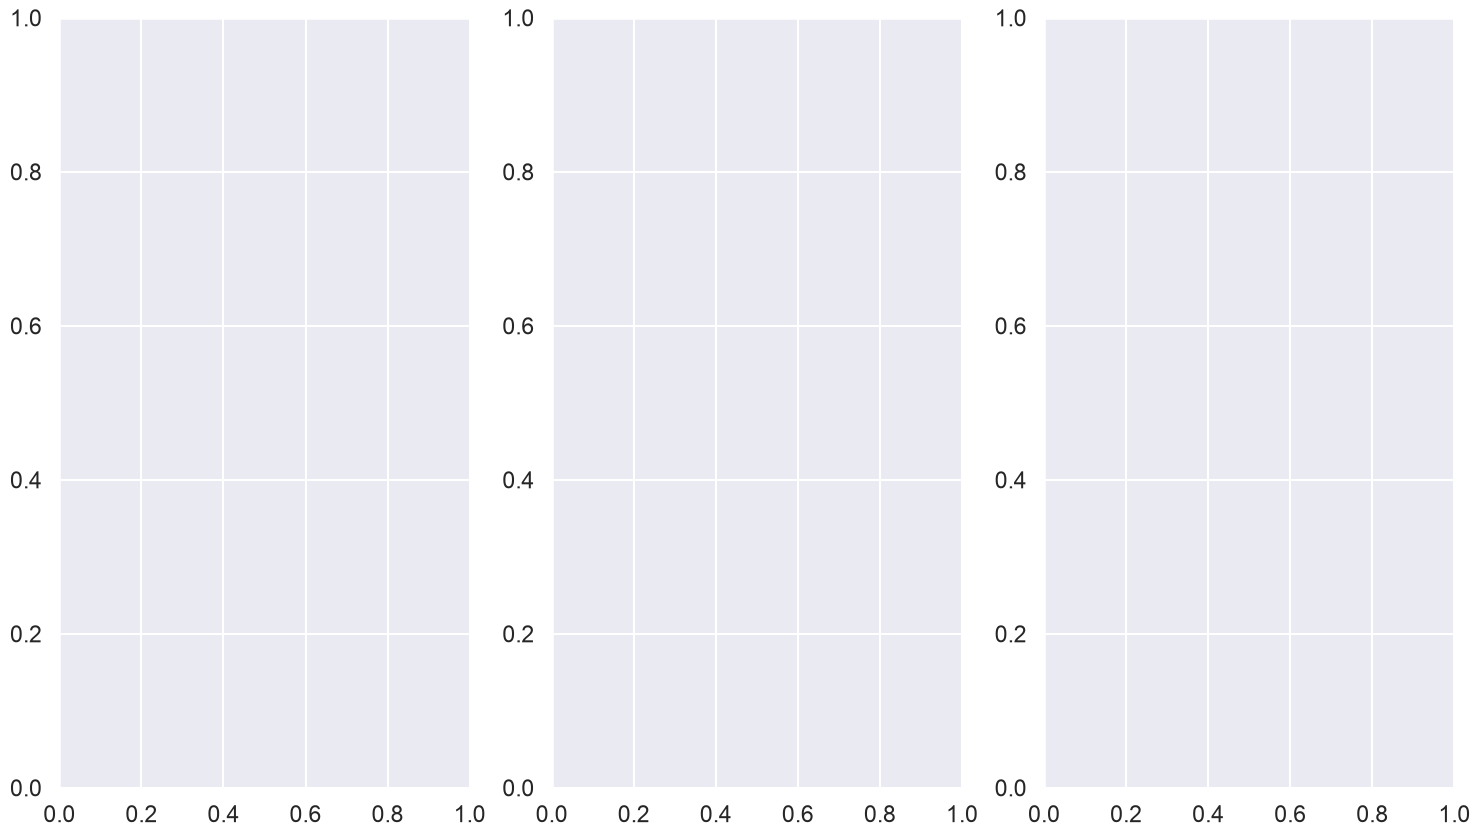

In [ ]:
# Your code here
contingency_table = pd.crosstab(clean["species"], clean["island"])

fig, axes = plt.subplots(1, 3, figsize=(18, 10))

# 1. heatmap
sns.heatmap(clean, ax)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, ax=ax, cmap=diverging, vmin=-1, vmax=1, center=0,
            annot=True, fmt='+.2f', square=True, linewidths=1, linecolor='white',
            cbar_kws=dict(label="Pearson's r"))
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_title('Correlations — pooled over all species')
plt.show()

### Exercise 2 — Does the paradox appear everywhere?

Repeat step 7 for `flipper_length_mm` against `body_mass_g`: compute the pooled
correlation and the three per-species correlations, and draw the matching figure.
Does aggregation mislead here as well? Why (not)?

In [ ]:
# Your code here


### Exercise 3 — Make the final figure survive a photocopier

Take the pass-4 figure from step 11 and make it work in pure greyscale: no hue, only
lightness, marker shape and position. You may change anything except the data.

In [ ]:
# Your code here


### Exercise 4 — Fix the pie

Replace the pie chart from step 12 with a chart that answers the question *"how are the
333 penguins distributed over species, island and sex?"* in a single figure.

In [ ]:
# Your code here


## Sources

K. B. Gorman, T. D. Williams, and W. R. Fraser. 2014. "Ecological Sexual Dimorphism and Environmental Variability within a Community of Antarctic Penguins (Genus *Pygoscelis*)." PLoS ONE 9 (3): e90081. doi:10.1371/journal.pone.0090081. The original study the measurements come from.

A. M. Horst, A. P. Hill, and K. B. Gorman. 2020. *palmerpenguins: Palmer Archipelago (Antarctica) Penguin Data*. doi:10.5281/zenodo.3960218. Released under [CC0 1.0](https://creativecommons.org/publicdomain/zero/1.0/); the data were collected by Dr Kristen Gorman and the [Palmer Station Antarctica LTER](https://pallter.marine.rutgers.edu/), a member of the Long Term Ecological Research Network. The copy in `data/penguins.csv` is the version shipped with seaborn.

W. S. Cleveland and R. McGill. 1984. "Graphical Perception: Theory, Experimentation, and Application to the Development of Graphical Methods." Journal of the American Statistical Association 79 (387): 531–554. doi:10.1080/01621459.1984.10478080. The ranking of visual encodings used in step 12.

A. Krause, N. Rennie, and B. Tarran. 2024. "Best Practices for Data Visualisation." Royal Statistical Society. Licensed CC BY 4.0. doi:10.5281/zenodo.10600718. The principles this demo applies, as condensed in notebook 05.

E. H. Simpson. 1951. "The Interpretation of Interaction in Contingency Tables." Journal of the Royal Statistical Society: Series B 13 (2): 238–241. The paradox of step 7.

M. L. Waskom. 2021. "seaborn: statistical data visualization." Journal of Open Source Software 6 (60): 3021. doi:10.21105/joss.03021.

<div style="background:linear-gradient(90deg,#e3f2fd,#e8f5e9);border:1px solid #90caf9;border-radius:8px;padding:1em 1.4em;margin:1.4em 0 0 0;">
  <strong>📚 Inspiration / Further Reading</strong>
  <ul style="margin:0.5em 0 0 0;">
    <li><a href="https://allisonhorst.github.io/palmerpenguins/" target="_blank" rel="noopener">palmerpenguins &ndash; the data set and its artwork</a></li>
    <li><a href="https://seaborn.pydata.org/examples/index.html" target="_blank" rel="noopener">seaborn example gallery</a></li>
    <li><a href="https://matplotlib.org/stable/gallery/" target="_blank" rel="noopener">matplotlib gallery</a></li>
    <li><a href="https://www.data-to-viz.com/" target="_blank" rel="noopener">From Data to Viz &ndash; which chart for which data</a></li>
    <li><a href="https://royal-statistical-society.github.io/datavisguide/" target="_blank" rel="noopener">Royal Statistical Society &ndash; Best Practices for Data Visualisation</a></li>
  </ul>
</div>